In [1]:
import os
import cv2
import math
import random
import zipfile
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
from tqdm.auto import tqdm
from PIL import Image
from skimage.metrics import structural_similarity as compare_ssim

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
import torchvision.transforms.functional as TF

train_matches = glob("/kaggle/input/**/train_data", recursive=True)
test_matches = glob("/kaggle/input/**/test_lr", recursive=True)

assert len(train_matches) > 0, f"train_data not found! Contents of /kaggle/input: {os.listdir('/kaggle/input')}"
assert len(test_matches) > 0, f"test_lr not found! Contents of /kaggle/input: {os.listdir('/kaggle/input')}"

TRAIN_DIR = train_matches[0]
TEST_DIR = test_matches[0]
INPUT_DIR = os.path.dirname(TRAIN_DIR)

PROJECT_DIR = "/kaggle/working"
SAVE_DIR = os.path.join(PROJECT_DIR, "saved_model_30db")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results_30db")
SUBMISSION_DIR = os.path.join(PROJECT_DIR, "submission_30db")

for folder in [SAVE_DIR, RESULTS_DIR, SUBMISSION_DIR]:
    os.makedirs(folder, exist_ok=True)

print("Kaggle environment ready!")
print("Detected Input directory:", INPUT_DIR)
print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR:", TEST_DIR)

Kaggle environment ready!
Detected Input directory: /kaggle/input/datasets/maripossa/dataset
TRAIN_DIR: /kaggle/input/datasets/maripossa/dataset/train_data
TEST_DIR: /kaggle/input/datasets/maripossa/dataset/test_lr


In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SCALE = 4
WIDTH = 96
NUM_BLOCKS = 24          
LR_PATCH_SIZE = 64       
REPEAT_FACTOR = 4        

BATCH_SIZE = 16
EPOCHS = 120             
LEARNING_RATE = 1e-3     
WEIGHT_DECAY = 0.0       

BEST_MODEL_PATH = os.path.join(SAVE_DIR, "best_nafnet_sr_30db.pth")

print(f"Device: {DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
print(f"Architecture: NAFNet-SR | Width: {WIDTH} | Blocks: {NUM_BLOCKS} | Scale: x{SCALE}")

Device: cuda (Tesla T4)
Architecture: NAFNet-SR | Width: 96 | Blocks: 24 | Scale: x4


In [3]:
class PairedSRDataset(Dataset):
    def __init__(self, hr_dir, lr_dir, filenames, lr_patch_size=64, is_train=True, repeat=1):
        self.hr_dir = hr_dir
        self.lr_dir = lr_dir
        self.filenames = filenames
        self.lr_patch_size = lr_patch_size
        self.is_train = is_train
        self.repeat = repeat if is_train else 1

        sample_hr = Image.open(os.path.join(hr_dir, self.filenames[0]))
        sample_lr = Image.open(os.path.join(lr_dir, self.filenames[0]))
        self.scale = sample_hr.width // sample_lr.width

    def __len__(self):
        return len(self.filenames) * self.repeat

    def __getitem__(self, idx):
        fname = self.filenames[idx % len(self.filenames)]
        hr_img = Image.open(os.path.join(self.hr_dir, fname)).convert("RGB")
        lr_img = Image.open(os.path.join(self.lr_dir, fname)).convert("RGB")

        if self.is_train:
            lr_w, lr_h = lr_img.size
            ps = self.lr_patch_size
            s = self.scale

            if lr_h >= ps and lr_w >= ps:
                top = random.randint(0, lr_h - ps)
                left = random.randint(0, lr_w - ps)
                lr_img = lr_img.crop((left, top, left + ps, top + ps))
                hr_img = hr_img.crop((left * s, top * s, (left + ps) * s, (top + ps) * s))

            hr = TF.to_tensor(hr_img)
            lr = TF.to_tensor(lr_img)

            if random.random() > 0.5:
                lr = torch.flip(lr, [2])
                hr = torch.flip(hr, [2])

            if random.random() > 0.5:
                lr = torch.flip(lr, [1])
                hr = torch.flip(hr, [1])

            k = random.choice([0, 1, 2, 3])
            if k > 0:
                lr = torch.rot90(lr, k, [1, 2])
                hr = torch.rot90(hr, k, [1, 2])

            if random.random() > 0.5:
                perm = torch.randperm(3)
                lr = lr[perm, :, :]
                hr = hr[perm, :, :]
        else:
            hr = TF.to_tensor(hr_img)
            lr = TF.to_tensor(lr_img)

        return lr, hr

def create_dataloaders(train_dir, batch_size=16, val_ratio=0.05, lr_patch_size=64, repeat=4):
    hr_dir = os.path.join(train_dir, "HR")
    lr_dir = os.path.join(train_dir, "LR")

    hr_files = set(os.listdir(hr_dir))
    lr_files = set(os.listdir(lr_dir))
    filenames = sorted(list(hr_files.intersection(lr_files)))
    assert len(filenames) > 0, f"No matching images between {hr_dir} and {lr_dir}"

    val_size = max(1, int(len(filenames) * val_ratio))
    train_files = filenames[:-val_size]
    val_files = filenames[-val_size:]

    train_ds = PairedSRDataset(hr_dir, lr_dir, train_files, lr_patch_size=lr_patch_size, is_train=True, repeat=repeat)
    val_ds = PairedSRDataset(hr_dir, lr_dir, val_files, is_train=False, repeat=1)

    print(f"Total paired images: {len(filenames)} | Train: {len(train_files)} (x{repeat} = {len(train_ds)} patches/epoch) | Val: {len(val_files)}")

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True, drop_last=True)
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=2, pin_memory=True)
    return train_loader, val_loader, train_ds

train_loader, val_loader, train_dataset = create_dataloaders(
    TRAIN_DIR, batch_size=BATCH_SIZE, val_ratio=0.05, lr_patch_size=LR_PATCH_SIZE, repeat=REPEAT_FACTOR
)

Total paired images: 1200 | Train: 1140 (x4 = 4560 patches/epoch) | Val: 60


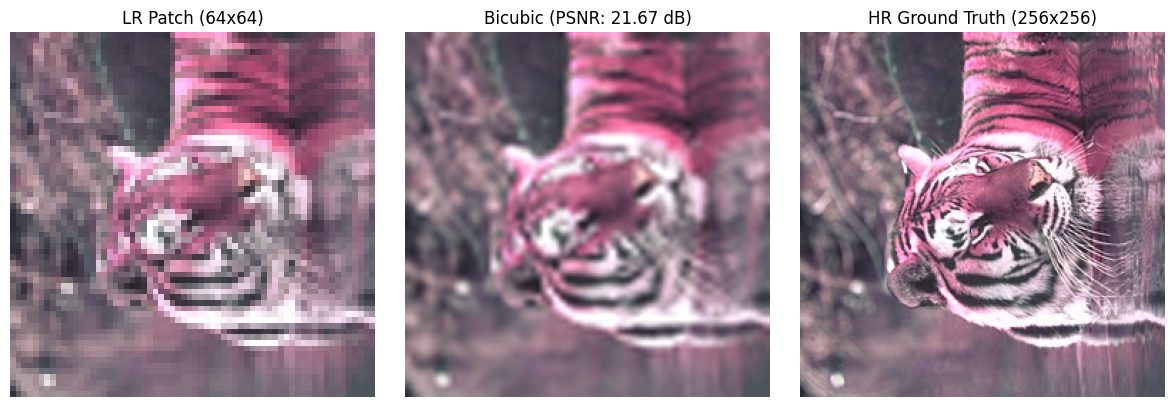

In [4]:
def calculate_psnr_rgb(sr, hr, crop_border=4):
    sr = sr.detach().cpu().numpy().transpose(1, 2, 0)
    hr = hr.detach().cpu().numpy().transpose(1, 2, 0)
    if crop_border > 0:
        sr = sr[crop_border:-crop_border, crop_border:-crop_border, :]
        hr = hr[crop_border:-crop_border, crop_border:-crop_border, :]
    mse = np.mean((sr - hr) ** 2, dtype=np.float64)
    if mse == 0:
        return float('inf')
    return 20.0 * math.log10(1.0 / math.sqrt(mse))

def calculate_psnr_y(sr, hr, crop_border=4):
    sr = (sr.detach().cpu().numpy().transpose(1, 2, 0) * 255.0).round().astype(np.float64)
    hr = (hr.detach().cpu().numpy().transpose(1, 2, 0) * 255.0).round().astype(np.float64)
    sr_y = 16.0 + (65.481 * sr[:, :, 0] + 128.553 * sr[:, :, 1] + 24.966 * sr[:, :, 2]) / 255.0
    hr_y = 16.0 + (65.481 * hr[:, :, 0] + 128.553 * hr[:, :, 1] + 24.966 * hr[:, :, 2]) / 255.0
    if crop_border > 0:
        sr_y = sr_y[crop_border:-crop_border, crop_border:-crop_border]
        hr_y = hr_y[crop_border:-crop_border, crop_border:-crop_border]
    mse = np.mean((sr_y - hr_y) ** 2)
    if mse == 0:
        return float('inf')
    return 20.0 * math.log10(255.0 / math.sqrt(mse))

lr_sample, hr_sample = train_dataset[0]
lr_up = torch.clamp(F.interpolate(lr_sample.unsqueeze(0), size=(256, 256), mode="bicubic", align_corners=False)[0], 0.0, 1.0)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(lr_sample.permute(1, 2, 0))
plt.title("LR Patch (64x64)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(lr_up.permute(1, 2, 0))
plt.title(f"Bicubic (PSNR: {calculate_psnr_rgb(lr_up, hr_sample):.2f} dB)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(hr_sample.permute(1, 2, 0))
plt.title("HR Ground Truth (256x256)")
plt.axis("off")
plt.tight_layout()
plt.show()

In [5]:
class LayerNorm2d(nn.Module):
    def __init__(self, channels, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(channels))
        self.bias = nn.Parameter(torch.zeros(channels))
        self.eps = eps

    def forward(self, x):
        u = x.mean(1, keepdim=True)
        s = (x - u).pow(2).mean(1, keepdim=True)
        x = (x - u) / torch.sqrt(s + self.eps)
        return self.weight[:, None, None] * x + self.bias[:, None, None]

class SimpleGate(nn.Module):
    def forward(self, x):
        x1, x2 = x.chunk(2, dim=1)
        return x1 * x2

class NAFBlockSR(nn.Module):
    def __init__(self, c, dw_expand=2, ffn_expand=2):
        super().__init__()
        dw_channel = c * dw_expand
        self.conv1 = nn.Conv2d(c, dw_channel, kernel_size=1, padding=0, stride=1, bias=True)
        self.conv2 = nn.Conv2d(dw_channel, dw_channel, kernel_size=3, padding=1, stride=1, groups=dw_channel, bias=True)
        self.conv3 = nn.Conv2d(dw_channel // 2, c, kernel_size=1, padding=0, stride=1, bias=True)

        self.sca = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(dw_channel // 2, dw_channel // 2, kernel_size=1, padding=0, stride=1, bias=True),
        )

        self.sg = SimpleGate()

        ffn_channel = ffn_expand * c
        self.conv4 = nn.Conv2d(c, ffn_channel, kernel_size=1, padding=0, stride=1, bias=True)
        self.conv5 = nn.Conv2d(ffn_channel // 2, c, kernel_size=1, padding=0, stride=1, bias=True)

        self.norm1 = LayerNorm2d(c)
        self.norm2 = LayerNorm2d(c)

        self.beta = nn.Parameter(torch.zeros((1, c, 1, 1)), requires_grad=True)
        self.gamma = nn.Parameter(torch.zeros((1, c, 1, 1)), requires_grad=True)

    def forward(self, inp):
        x = self.norm1(inp)
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.sg(x)
        x = x * self.sca(x)
        x = self.conv3(x)
        y = inp + x * self.beta

        x = self.conv4(self.norm2(y))
        x = self.sg(x)
        x = self.conv5(x)
        return y + x * self.gamma

class NAFNetSR(nn.Module):
    def __init__(self, up_scale=4, width=96, num_blks=24):
        super().__init__()
        self.up_scale = up_scale
        self.intro = nn.Conv2d(3, width, kernel_size=3, padding=1, stride=1, bias=True)
        self.body = nn.Sequential(*[NAFBlockSR(width) for _ in range(num_blks)])
        self.conv_after_body = nn.Conv2d(width, width, kernel_size=3, padding=1, stride=1, bias=True)

        if up_scale == 4:
            self.upsample = nn.Sequential(
                nn.Conv2d(width, width * 4, kernel_size=3, padding=1, bias=True),
                nn.PixelShuffle(2),
                nn.GELU(),
                nn.Conv2d(width, width * 4, kernel_size=3, padding=1, bias=True),
                nn.PixelShuffle(2),
                nn.Conv2d(width, 3, kernel_size=3, padding=1, bias=True)
            )
        else:
            self.upsample = nn.Sequential(
                nn.Conv2d(width, 3 * (up_scale ** 2), kernel_size=3, padding=1, bias=True),
                nn.PixelShuffle(up_scale)
            )

    def forward(self, x):
        base = F.interpolate(x, scale_factor=self.up_scale, mode="bicubic", align_corners=False)
        feat = self.intro(x)
        res = self.conv_after_body(self.body(feat)) + feat
        out = self.upsample(res)
        return out + base

model = NAFNetSR(up_scale=SCALE, width=WIDTH, num_blks=NUM_BLOCKS).to(DEVICE)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model initialized successfully | Trainable Parameters: {total_params / 1e6:.2f}M")

Model initialized successfully | Trainable Parameters: 2.38M


In [6]:
class HybridSRLoss(nn.Module):
    def __init__(self, eps=1e-6, fft_weight=0.05):
        super().__init__()
        self.eps = eps
        self.fft_weight = fft_weight

    def forward(self, pred, target):
        charb_loss = torch.mean(torch.sqrt((pred - target) ** 2 + self.eps))
        pred_fft = torch.fft.rfft2(pred.float(), norm="ortho")
        target_fft = torch.fft.rfft2(target.float(), norm="ortho")
        fft_loss = F.l1_loss(torch.view_as_real(pred_fft), torch.view_as_real(target_fft))
        return charb_loss + self.fft_weight * fft_loss

def forward_x8(model, x):
    preds = []
    for k in range(4):
        for flip in [False, True]:
            aug = torch.rot90(x, k, [2, 3])
            if flip:
                aug = torch.flip(aug, [3])
            out = model(aug)
            if flip:
                out = torch.flip(out, [3])
            out = torch.rot90(out, -k, [2, 3])
            preds.append(out)
    return torch.stack(preds, dim=0).mean(dim=0)

In [7]:
criterion = HybridSRLoss(eps=1e-6, fft_weight=0.05)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY, betas=(0.9, 0.99))
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
scaler = torch.amp.GradScaler("cuda")

bicubic_rgb_psnr, bicubic_y_psnr = 0.0, 0.0
for lr_val, hr_val in val_loader:
    bic = torch.clamp(F.interpolate(lr_val, scale_factor=SCALE, mode="bicubic", align_corners=False), 0.0, 1.0)
    bicubic_rgb_psnr += calculate_psnr_rgb(bic[0], hr_val[0], crop_border=4)
    bicubic_y_psnr += calculate_psnr_y(bic[0], hr_val[0], crop_border=4)
bicubic_rgb_psnr /= len(val_loader)
bicubic_y_psnr /= len(val_loader)
print(f"Validation Baseline (Bicubic) -> RGB PSNR: {bicubic_rgb_psnr:.2f} dB | Y-Channel PSNR: {bicubic_y_psnr:.2f} dB")

best_psnr = 0.0
history_loss, history_psnr_rgb, history_psnr_y = [], [], []

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch:03d}/{EPOCHS:03d}", leave=False)
    for lr_imgs, hr_imgs in pbar:
        lr_imgs = lr_imgs.to(DEVICE, non_blocking=True)
        hr_imgs = hr_imgs.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda"):
            preds = model(lr_imgs)
            loss = criterion(preds, hr_imgs)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        pbar.set_postfix({"loss": f"{loss.item():.4f}", "lr": f"{optimizer.param_groups[0]['lr']:.2e}"})

    scheduler.step()
    avg_loss = running_loss / len(train_loader)
    history_loss.append(avg_loss)

    if epoch % 2 == 0 or epoch == 1 or epoch == EPOCHS:
        model.eval()
        val_rgb_psnr, val_y_psnr = 0.0, 0.0
        with torch.no_grad():
            for lr_val, hr_val in val_loader:
                lr_val = lr_val.to(DEVICE, non_blocking=True)
                hr_val = hr_val.to(DEVICE, non_blocking=True)
                with torch.amp.autocast("cuda"):
                    sr_val = torch.clamp(model(lr_val), 0.0, 1.0)
                val_rgb_psnr += calculate_psnr_rgb(sr_val[0], hr_val[0], crop_border=4)
                val_y_psnr += calculate_psnr_y(sr_val[0], hr_val[0], crop_border=4)

        val_rgb_psnr /= len(val_loader)
        val_y_psnr /= len(val_loader)
        history_psnr_rgb.append((epoch, val_rgb_psnr))
        history_psnr_y.append((epoch, val_y_psnr))

        saved_str = ""
        if val_rgb_psnr > best_psnr:
            best_psnr = val_rgb_psnr
            torch.save(model.state_dict(), BEST_MODEL_PATH)
            saved_str = " [BEST SAVED]"

        print(f"Epoch {epoch:03d}/{EPOCHS:03d} | Loss: {avg_loss:.4f} | Val RGB PSNR: {val_rgb_psnr:.2f} dB | Val Y PSNR: {val_y_psnr:.2f} dB{saved_str}")

Validation Baseline (Bicubic) -> RGB PSNR: 23.83 dB | Y-Channel PSNR: 25.26 dB


Epoch 001/120:   0%|          | 0/285 [00:00<?, ?it/s]

Epoch 001/120 | Loss: 0.0412 | Val RGB PSNR: 24.55 dB | Val Y PSNR: 26.00 dB [BEST SAVED]


Epoch 002/120:   0%|          | 0/285 [00:00<?, ?it/s]

Epoch 002/120 | Loss: 0.0382 | Val RGB PSNR: 24.85 dB | Val Y PSNR: 26.31 dB [BEST SAVED]


Epoch 003/120:   0%|          | 0/285 [00:00<?, ?it/s]

... (189 outputs left out)

Epoch 118/120 | Loss: 0.0323 | Val RGB PSNR: 25.17 dB | Val Y PSNR: 26.61 dB


Epoch 119/120:   0%|          | 0/285 [00:00<?, ?it/s]

Epoch 120/120:   0%|          | 0/285 [00:00<?, ?it/s]

Epoch 120/120 | Loss: 0.0323 | Val RGB PSNR: 25.17 dB | Val Y PSNR: 26.61 dB


Evaluating Best Model with x8 TTA:   0%|          | 0/60 [00:00<?, ?it/s]


Final Best Model + x8 Self-Ensemble -> RGB PSNR: 25.40 dB | Y-Channel PSNR: 26.85 dB


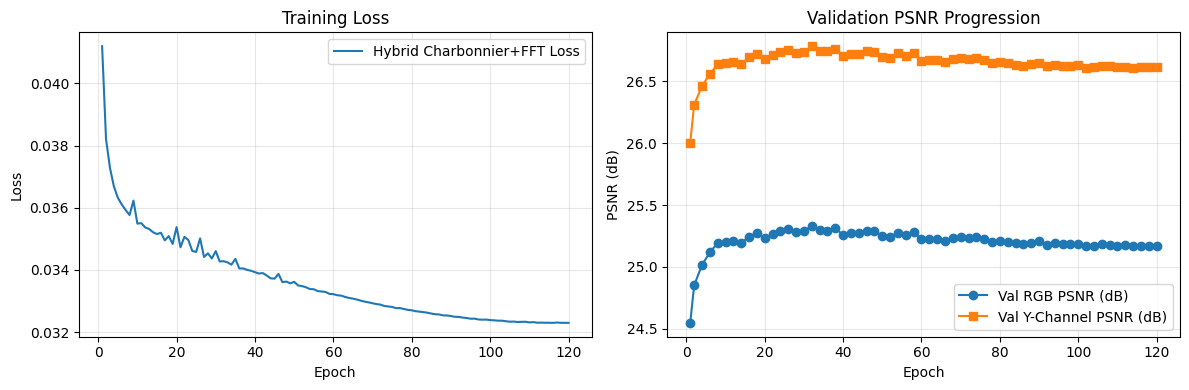

Generating Test SR Images:   0%|          | 0/20 [00:00<?, ?it/s]

Saved 20 super-resolved test images to /kaggle/working/submission_30db
Created submission archive: /kaggle/working/submission_30db.zip


In [8]:
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=DEVICE))
model.eval()

tta_rgb_psnr, tta_y_psnr = 0.0, 0.0
with torch.no_grad():
    for lr_val, hr_val in tqdm(val_loader, desc="Evaluating Best Model with x8 TTA"):
        lr_val = lr_val.to(DEVICE)
        hr_val = hr_val.to(DEVICE)
        with torch.amp.autocast("cuda"):
            sr_tta = torch.clamp(forward_x8(model, lr_val), 0.0, 1.0)
        tta_rgb_psnr += calculate_psnr_rgb(sr_tta[0], hr_val[0], crop_border=4)
        tta_y_psnr += calculate_psnr_y(sr_tta[0], hr_val[0], crop_border=4)

tta_rgb_psnr /= len(val_loader)
tta_y_psnr /= len(val_loader)
print(f"\nFinal Best Model + x8 Self-Ensemble -> RGB PSNR: {tta_rgb_psnr:.2f} dB | Y-Channel PSNR: {tta_y_psnr:.2f} dB")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, len(history_loss) + 1), history_loss, label="Hybrid Charbonnier+FFT Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.grid(True, alpha=0.3)
plt.legend()

plt.subplot(1, 2, 2)
epochs_logged = [x[0] for x in history_psnr_rgb]
plt.plot(epochs_logged, [x[1] for x in history_psnr_rgb], marker="o", label="Val RGB PSNR (dB)")
plt.plot(epochs_logged, [x[1] for x in history_psnr_y], marker="s", label="Val Y-Channel PSNR (dB)")
plt.xlabel("Epoch")
plt.ylabel("PSNR (dB)")
plt.title("Validation PSNR Progression")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

def generate_test_predictions(model, test_lr_dir, output_dir, device, use_tta=True):
    os.makedirs(output_dir, exist_ok=True)
    model.eval()

    IMAGE_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp")
    test_files = sorted([f for f in os.listdir(test_lr_dir) if f.lower().endswith(IMAGE_EXTENSIONS)])

    with torch.no_grad():
        for fname in tqdm(test_files, desc="Generating Test SR Images"):
            lr_path = os.path.join(test_lr_dir, fname)
            lr_img = Image.open(lr_path).convert("RGB")
            lr_tensor = TF.to_tensor(lr_img).unsqueeze(0).to(device)

            with torch.amp.autocast("cuda"):
                sr_tensor = forward_x8(model, lr_tensor) if use_tta else model(lr_tensor)
            sr_tensor = torch.clamp(sr_tensor.squeeze(0).float().cpu(), 0.0, 1.0)

            sr_img = TF.to_pil_image(sr_tensor)
            sr_img.save(os.path.join(output_dir, fname))

    print(f"Saved {len(test_files)} super-resolved test images to {output_dir}")

generate_test_predictions(model, TEST_DIR, SUBMISSION_DIR, DEVICE, use_tta=True)

zip_path = os.path.join(PROJECT_DIR, "submission_30db.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir(SUBMISSION_DIR)):
        zf.write(os.path.join(SUBMISSION_DIR, fname), arcname=fname)
print(f"Created submission archive: {zip_path}")